This example uses the "seeds" dataset from the UCI machine learning database. More info can be found here: https://archive-beta.ics.uci.edu/dataset/236/seeds

The data set can be used for the tasks of classification and cluster analysis.
To construct the data, seven geometric parameters of wheat kernels were measured: 
1. area A, 
2. perimeter P, 
3. compactness C = 4*pi*A/P^2, 
4. length of kernel,
5. width of kernel,
6. asymmetry coefficient
7. length of kernel groove.
8. variety

All of these parameters were real-valued continuous.

In [1]:
# import packages
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
# first we will download the data directly from the web
data_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt'

# Download data directly from UCI repo
data_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt'

data_cols = ['area', 'perimeter', 'compactness', 'length', 'width', 'asym', 'groove', 'variety']

# sep=r'\s+' handles varying tabs/spaces in the dataset file
data = pd.read_csv(data_url, sep=r'\s+', on_bad_lines='skip', names=data_cols, index_col=None)
data

,area,perimeter,compactness,length,width,asym,groove,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


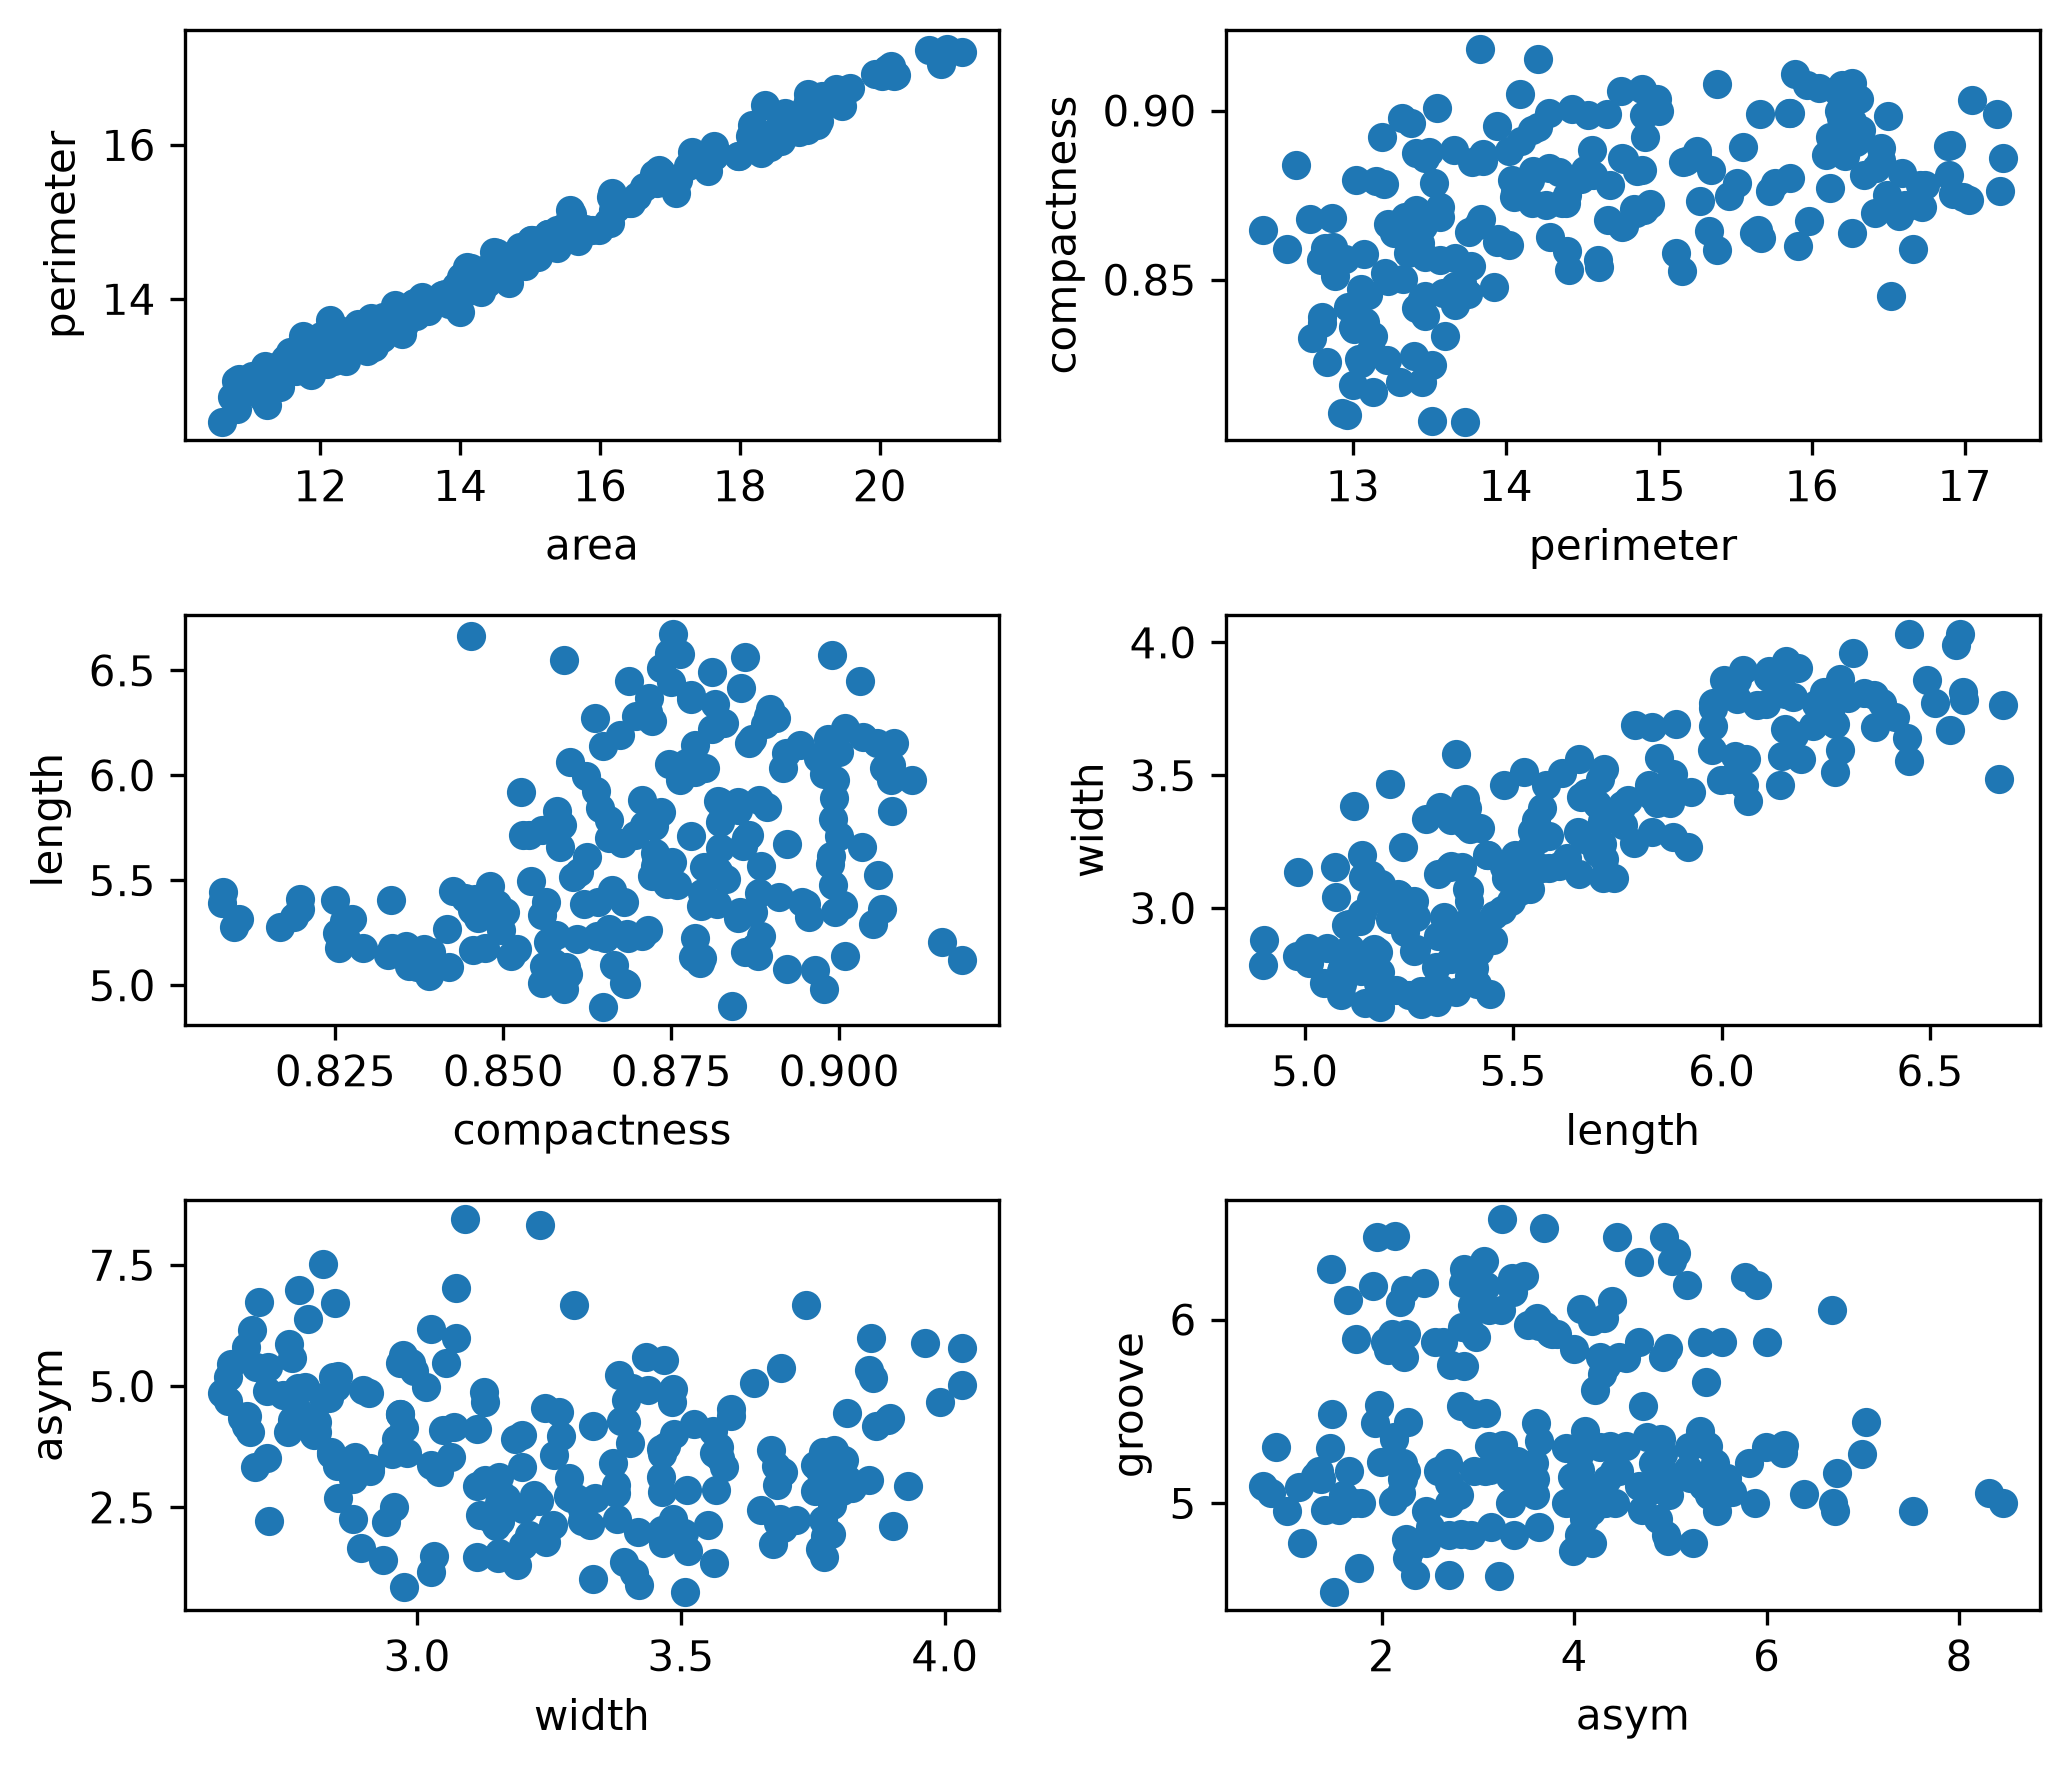

In [3]:
# take a quick look at the data
nrows, ncols = 3, 2
fig = plt.figure(figsize = (7,6), dpi = 300)

for i in range(1, 7): # everything except "variety"
    ax = fig.add_subplot(nrows, ncols, i)
    ax.scatter(data.iloc[:,i-1], data.iloc[:,i])
    ax.set_xlabel(data.columns[i-1])
    ax.set_ylabel(data.columns[i])

plt.tight_layout()
plt.show()

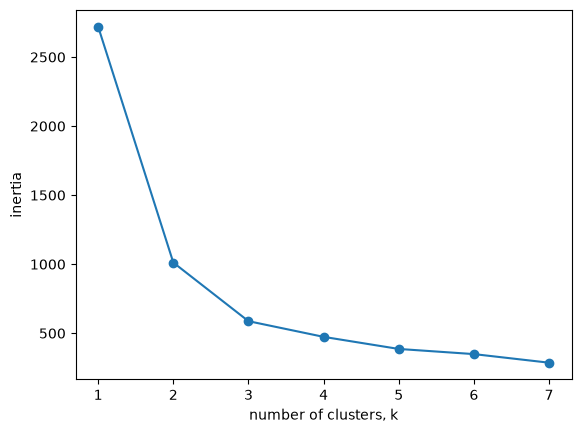

In [4]:
# how many clusters should we use?
# look at the trade off between inertia and number of clusters
inertias = []
ks = range(1, 8)

for k in ks:
    # Create a KMeans instance with k clusters: model
    model = KMeans(n_clusters = k, random_state = 42, n_init='auto')
    
    # Fit model to samples, we exclude the last column that contains the variety label
    model.fit(data.iloc[:,0:7])
    
    # Append the inertia to the list of inertias
    inertias.append(model.inertia_)
    
# Plot ks vs inertias
plt.plot(ks, inertias, '-o')
plt.xlabel('number of clusters, k')
plt.ylabel('inertia')
plt.xticks(ks)
plt.show()

In [5]:
# Create a KMeans model with 3 clusters: model
model = KMeans(n_clusters = 3, n_init='auto', random_state=42) # set random state to get reproducible results in the cross-tabulation table

# Fit model to points
model.fit(data.iloc[:,0:7])

# get the centroids
centroids = model.cluster_centers_

# check the dimensions of the centroids
print(centroids.shape)

(3, 7)


In [6]:
# Use fit_predict to fit model and obtain cluster labels: labels
labels = model.fit_predict(data)

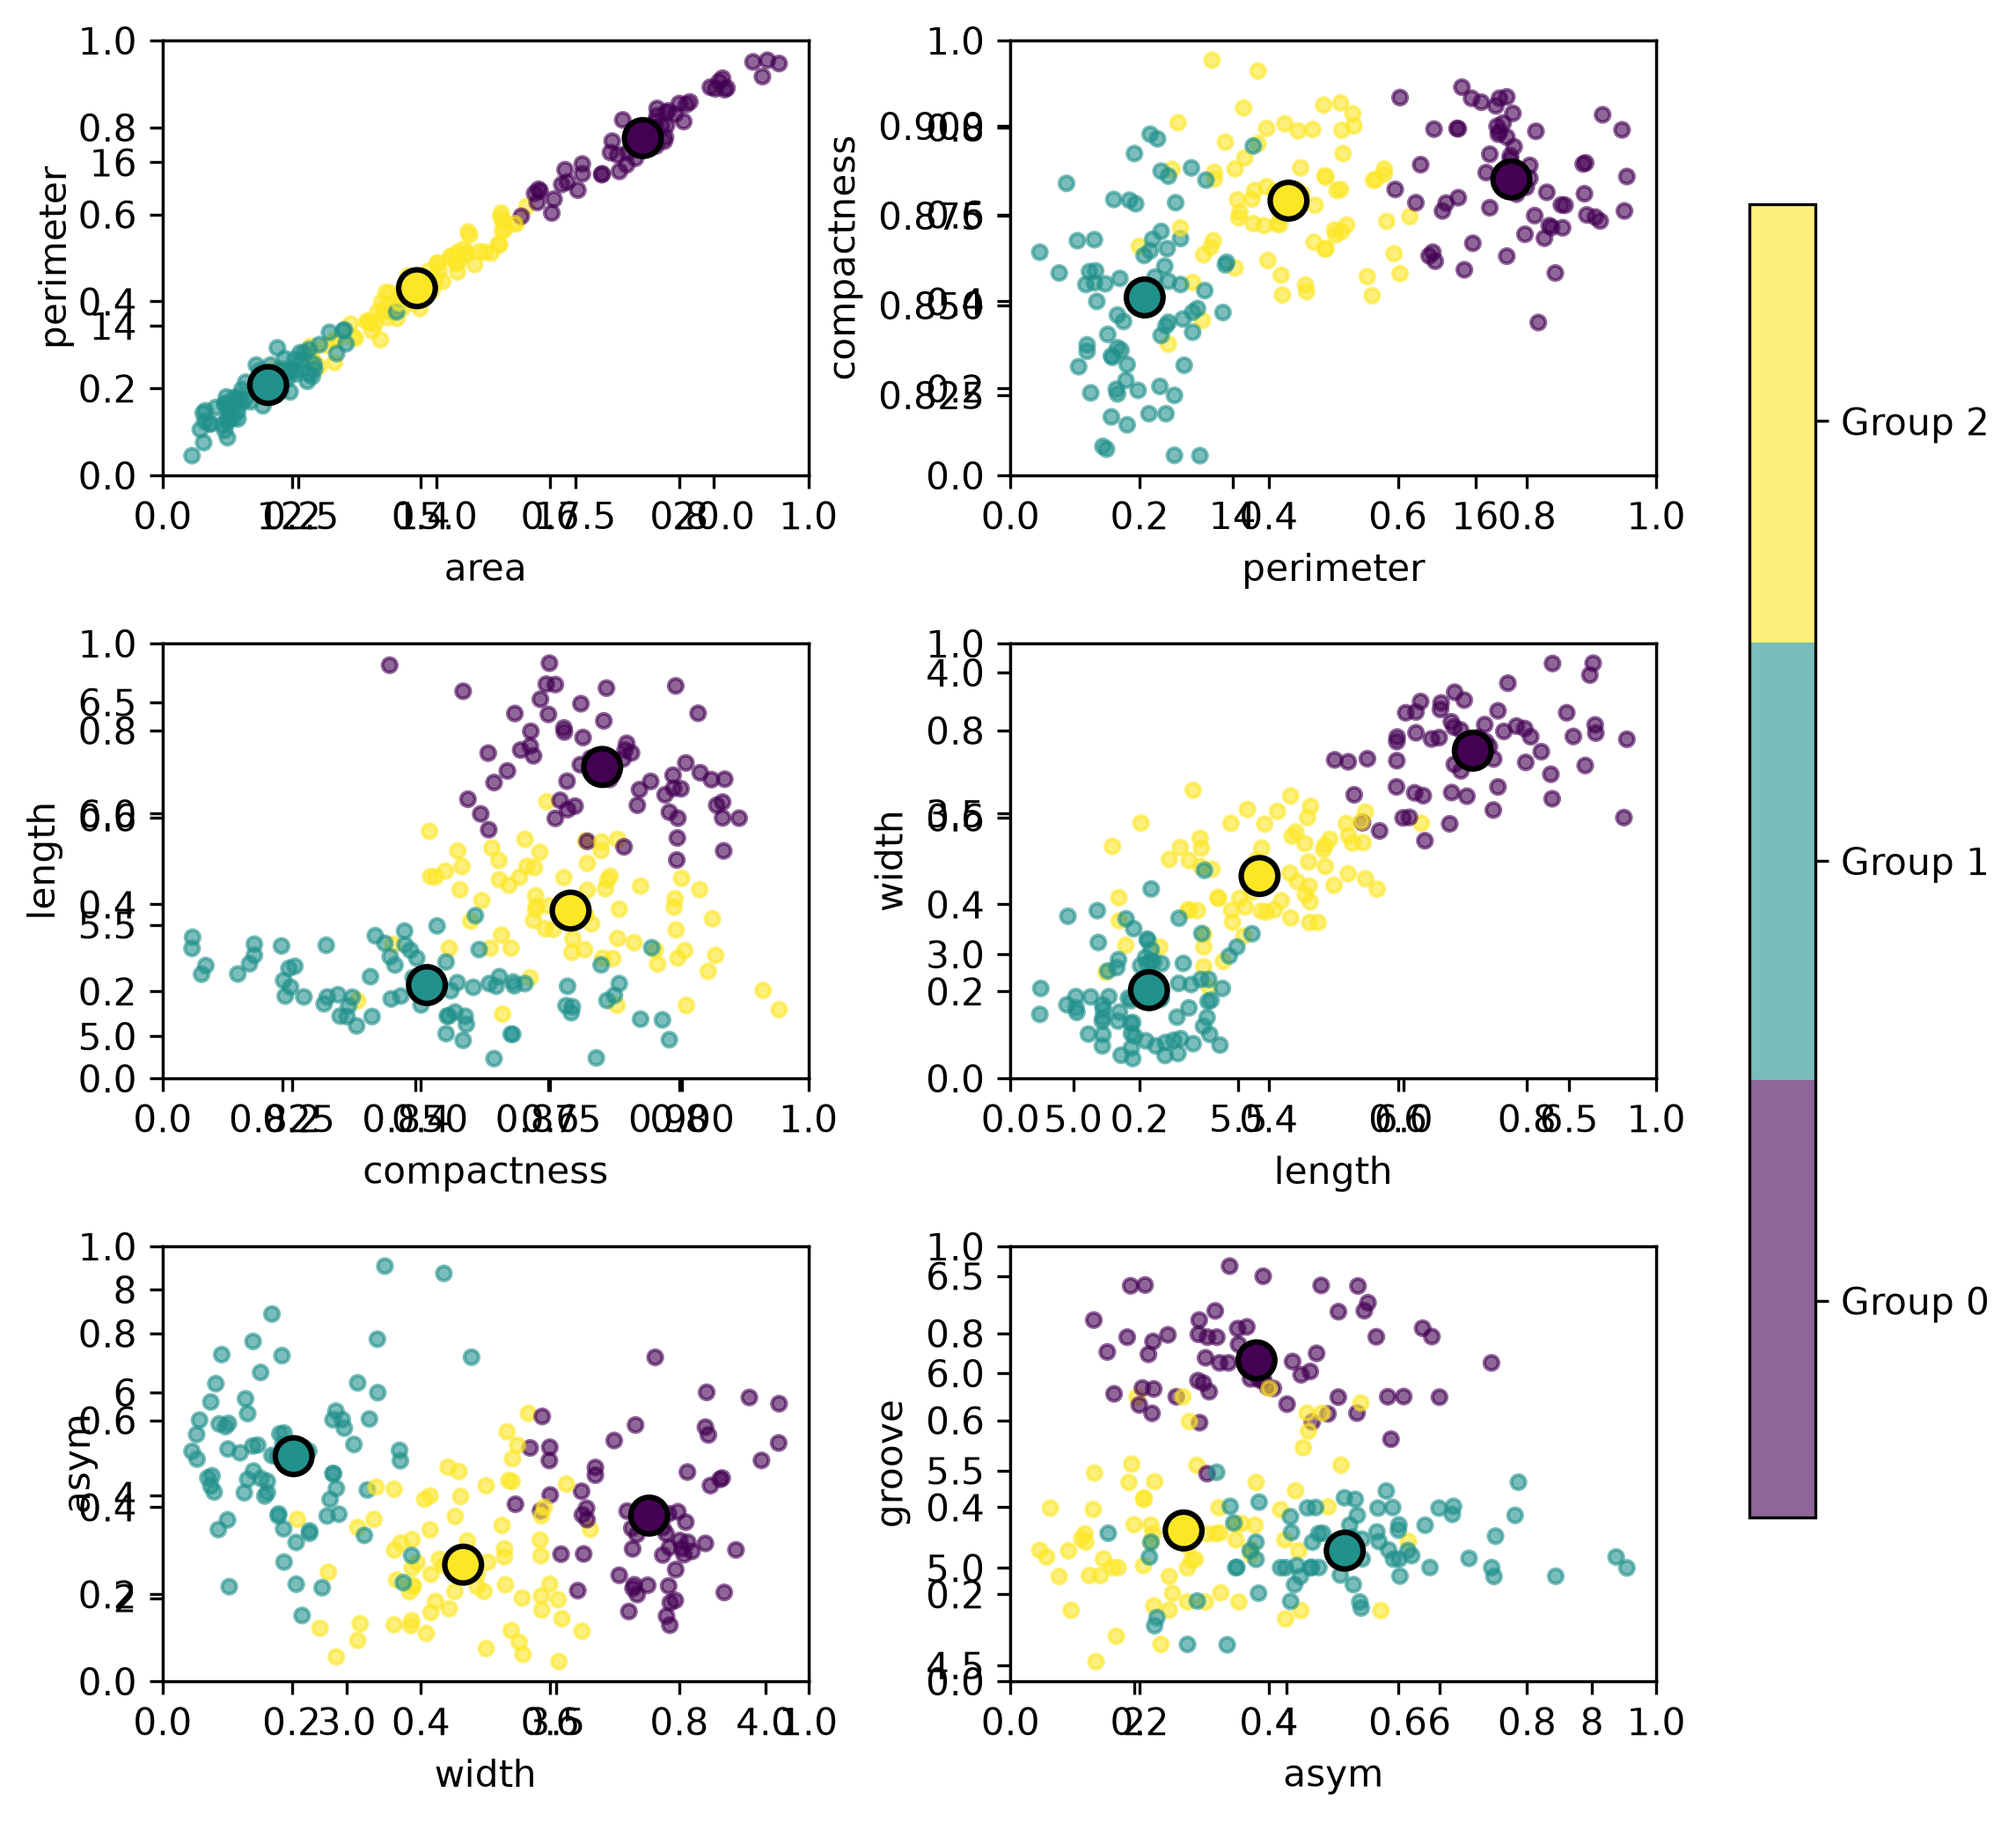

In [9]:
# check how the model centroids compare to the data
nrows, ncols = 3, 2
fig, axes = plt.subplots(nrows, ncols, figsize=(8, 7), dpi=300)

# Define a discrete colormap with 3 colors for the 3 centroids/groups
cmap = plt.colormaps['viridis'].resampled(3)
centroid_labels = np.array([0, 1, 2])  # Cluster IDs for the 3 centroids

for i in range(1, 7):
    ax = fig.add_subplot(nrows, ncols, i)
    
    # Scatter plot for dataset points colored by cluster labels
    sc = ax.scatter(
        data.iloc[:, i-1], 
        data.iloc[:, i], 
        c=labels, 
        cmap=cmap, 
        alpha=0.6, 
        s=15
    )
    
    # Scatter plot for centroids with distinct markers (e.g., 'X') colored by group
    ax.scatter(
        centroids[:, i-1], 
        centroids[:, i], 
        c=centroid_labels, 
        cmap=cmap, 
        marker='o', 
        s=100, 
        edgecolor='black', 
        linewidth=1.5
    )
    
    ax.set_xlabel(data.columns[i-1])
    ax.set_ylabel(data.columns[i])

plt.tight_layout()

# Add a single colorbar for the entire figure with discrete ticks for the 3 groups
cbar = fig.colorbar(sc, ax=fig.axes, orientation='vertical', shrink=0.8, ticks=[0.33, 1.0, 1.67])
cbar.ax.set_yticklabels(['Group 0', 'Group 1', 'Group 2'])  # Customize group names if needed

plt.show()

In [10]:
# Even though this is clustering (unsupervised), not classification (supervised),
# Sometimes we know something about how the data "might" be grouped: our hypothesis.
# We can check how well our clustering worked compared to our hypothesis.
# This is sometimes called "Domain validation"

# Create a DataFrame with labels and varieties as columns: df
df = pd.DataFrame({'labels': labels, 'varieties': data.variety})

# Create a cross-tabulation of the original variety from the seeds data table and the model prediction
ct = pd.crosstab(df['labels'], df['varieties'])
print(ct)



varieties   1   2   3
labels               
0           1  60   0
1           5   0  70
2          64  10   0


In [11]:
# We can see which is which in this example using "majority vote rule" easily.
# In some examples you might need to map it more intentionally to know 
# which predicted cluster/group corresponds to which known variety.

# Map each cluster label to the most frequent variety in that cluster
# idxmax is the index label of the maximum value.
# axis=1 tells pandas to go horizontally across columns for each row.
# to_dict creates a python "dictionary" which is displayed in curly brackets {}
cluster_to_variety_map = ct.idxmax(axis=1).to_dict()
print(cluster_to_variety_map)

{0: 2, 1: 3, 2: 1}


In [12]:
# Calculate the number of correct predictions and % correct
correct = ct.max(axis=1).sum()
percent_correct = (ct.max(axis=1).sum() / ct.values.sum()) * 100
print(percent_correct)

92.38095238095238
